# 01 — EDA: Duolingo SLAM (en_es)

Duolingo SLAM (en_es) — người nói tiếng Tây Ban Nha học tiếng Anh (Dataverse ghi: *English learners who already speak Spanish*).
Token là từ tiếng Anh (I, am, a, boy...), prompt là tiếng Tây Ban Nha → ngôn ngữ **được học là tiếng Anh**.
**Chỉ EDA — chưa tiền xử lý / chia tập** (làm ở bước riêng sau).

## Định dạng (đọc từ `starter_code/README.md` + `baseline.py`)
- Mỗi bài tập = một khối: dòng `# prompt:...`, dòng `# user:... days:... format:... session:... time:...`, rồi các dòng token.
- Dòng token: `instance_id  token  POS  morph_features  dependency_label  head  [label]`.
- `label`: cột 7 ở **train** (`0`=đúng, `1`=SAI); **dev/test** không có label ở file chính → lấy từ `.dev.key` / `.test.key`.
- **correct = 1 − label** (label=1 nghĩa là trả lời sai).
- Ánh xạ DKT: `user`=chuỗi người học, `token`=item/skill, `days`=thứ tự thời gian.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

sys.path.append(str(Path.cwd().parent))  # import config từ ml/
from config import DATA_DIR, set_seed
set_seed()

SLAM = Path(DATA_DIR) / 'data_en_es'
BASE = SLAM / 'en_es.slam.20190204'
print('Thư mục dữ liệu:', SLAM)

Thư mục dữ liệu: E:\KLTN-DKT-vocab\ml\data\data_en_es


In [2]:
def parse_slam(data_path, key_path=None):
    """Parse 1 file SLAM -> DataFrame(user, token, label, days, format, session, correct).
    key_path: file .key chứa nhãn cho dev/test (train đã có nhãn ở cột 7)."""
    labels = {}
    if key_path is not None:
        with open(key_path, encoding='utf-8') as f:
            for line in f:
                p = line.split()
                if len(p) == 2:
                    labels[p[0]] = int(p[1])
    rows = []
    user = days = fmt = sess = None
    with open(data_path, encoding='utf-8') as f:
        for line in f:
            line = line.rstrip('\n')
            if line.startswith('#'):
                if 'user:' in line:  # dòng metadata bài tập
                    meta = {}
                    for p in line.lstrip('#').split():
                        if ':' in p:
                            k, v = p.split(':', 1)
                            meta[k] = v
                    user = meta.get('user')
                    days = float(meta.get('days', 0) or 0)
                    fmt = meta.get('format')
                    sess = meta.get('session')
                continue  # dòng '# prompt:' bỏ qua
            if not line.strip():
                continue
            parts = line.split()
            label = int(float(parts[6])) if len(parts) >= 7 else labels.get(parts[0])
            rows.append((user, parts[1], label, days, fmt, sess))
    df = pd.DataFrame(rows, columns=['user', 'token', 'label', 'days', 'format', 'session'])
    for c in ['user', 'token', 'format', 'session']:
        df[c] = df[c].astype('category')
    df['correct'] = 1 - df['label']
    return df

In [3]:
%%time
train = parse_slam(f'{BASE}.train')
dev   = parse_slam(f'{BASE}.dev', f'{BASE}.dev.key')
test  = parse_slam(f'{BASE}.test', f'{BASE}.test.key')
len(train), len(dev), len(test)

CPU times: total: 11.7 s
Wall time: 12.1 s


(2622957, 387374, 386604)

In [4]:
train.head(6)

,user,token,label,days,format,session,correct
0,XEinXf5+,I,0,0.003,reverse_translate,lesson,1
1,XEinXf5+,am,0,0.003,reverse_translate,lesson,1
2,XEinXf5+,a,0,0.003,reverse_translate,lesson,1
3,XEinXf5+,boy,0,0.003,reverse_translate,lesson,1
4,XEinXf5+,I,0,0.005,reverse_translate,lesson,1
5,XEinXf5+,am,0,0.005,reverse_translate,lesson,1


## Kiểm tra nhãn thiếu (dev/test khớp file .key?)

In [5]:
# Mọi instance_id ở dev/test phải khớp file .key; nếu không sẽ ra nhãn NaN.
for name, df in [('dev', dev), ('test', test)]:
    n_missing = int(df['label'].isna().sum())
    if n_missing == 0:
        print(f'{name}: 0 nhãn thiếu — mọi instance_id đều khớp .key (OK)')
    else:
        pct = 100 * n_missing / len(df)
        print(f'{name}: CANH BAO {n_missing:,} interaction ({pct:.2f}%) thieu nhan '
              f'(instance_id khong co trong .key). Cach xu ly: kiem tra lai file .key, '
              f'hoac loai cac dong NaN truoc khi train.')

dev: 0 nhãn thiếu — mọi instance_id đều khớp .key (OK)
test: 0 nhãn thiếu — mọi instance_id đều khớp .key (OK)


## Thống kê tổng quan

In [6]:
def overview(df, name):
    return {
        'split': name,
        'interactions': len(df),
        'users': df['user'].nunique(),
        'unique_tokens': df['token'].nunique(),
        'correct_rate': round(df['correct'].mean(), 4),
        'mistake_rate': round(df['label'].mean(), 4),
    }

summary = pd.DataFrame([overview(train, 'train'), overview(dev, 'dev'), overview(test, 'test')])
summary

,split,interactions,users,unique_tokens,correct_rate,mistake_rate
0,train,2622957,2593,2226,0.8739,0.1261
1,dev,387374,2592,2071,0.8571,0.1429
2,test,386604,2593,2114,0.8492,0.1508


> Lưu ý: SLAM chia theo **thời gian** (cùng ~2.593 user, dev/test là giai đoạn sau của chính họ), không phải chia theo user. Điều này quan trọng khi thiết kế split cho DKT.

In [7]:
# Độ dài chuỗi (số interaction) mỗi user trên train
seq_len = train.groupby('user', observed=True).size()
seq_len.describe().round(1)

count    2593.0
mean     1011.6
std       651.4
min       103.0
25%       594.0
50%       835.0
75%      1219.0
max      8894.0
dtype: float64

## Số lần luyện lại mỗi cặp (user, token) — biện minh cho Knowledge Tracing

In [8]:
# Mỗi cặp (user, token) lặp bao nhiêu lần = một user gặp lại cùng một từ mấy lần
pair_counts = train.groupby(['user', 'token'], observed=True).size()
print('Phân bố số lần luyện lại mỗi cặp (user, token) trên train:')
print(pair_counts.describe().round(2))
print(f'\nTrung bình mỗi cặp (user, token) được luyện lại {pair_counts.mean():.1f} lần.')

Phân bố số lần luyện lại mỗi cặp (user, token) trên train:
count    814596.00
mean          3.22
std           8.25
min           1.00
25%           1.00
50%           2.00
75%           3.00
max         525.00
dtype: float64

Trung bình mỗi cặp (user, token) được luyện lại 3.2 lần.


> **Vì sao Knowledge Tracing có ý nghĩa ở đây:** trung bình mỗi từ được một user luyện lại nhiều lần theo thời gian, nên có thể **theo dõi tiến trình học một từ** (đúng/sai qua các lần lặp) — đúng bài toán mà DKT giải quyết (nếu mỗi từ chỉ xuất hiện một lần thì KT sẽ vô nghĩa).

## Biểu đồ

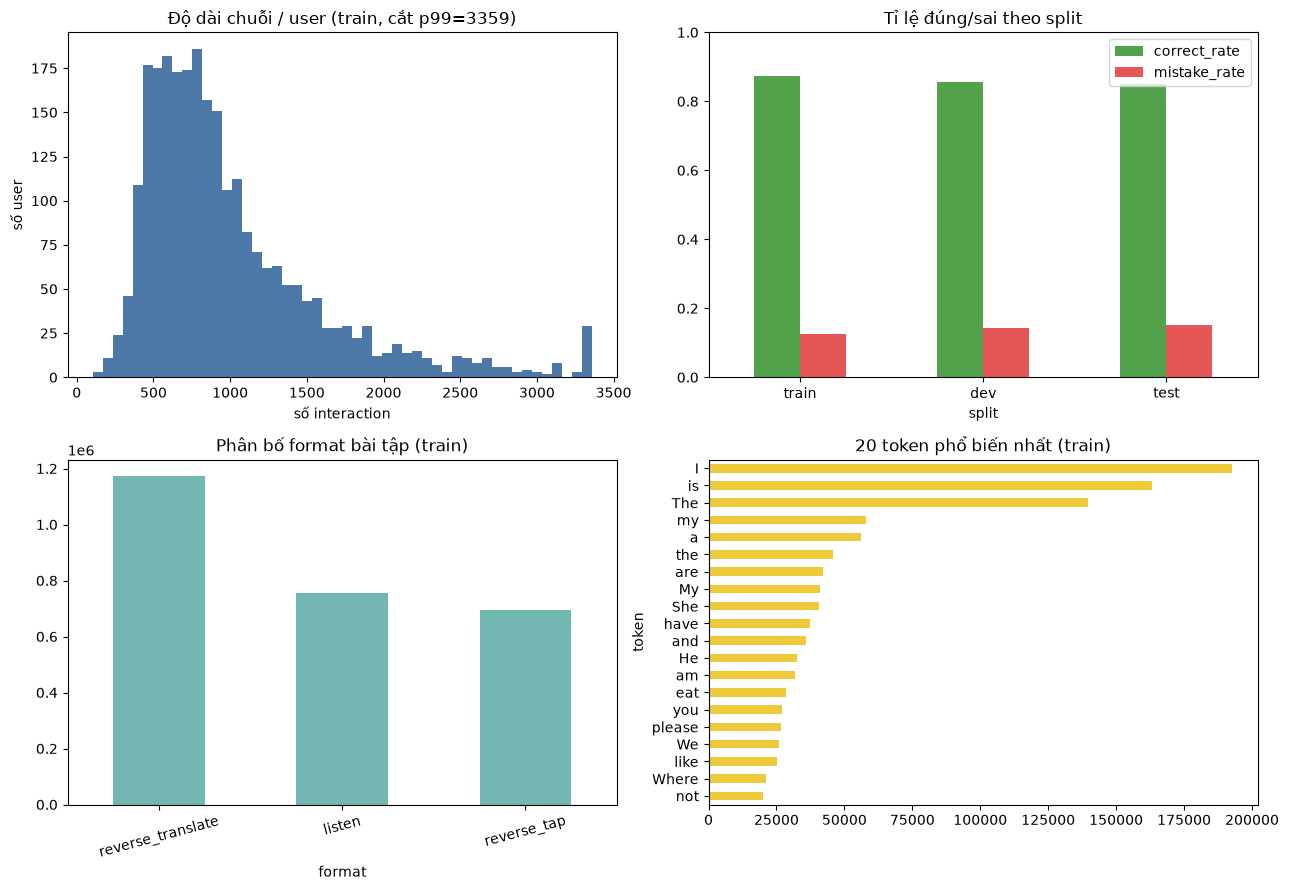

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# 1) Phân bố độ dài chuỗi / user (cắt ở p99 để dễ nhìn)
cap = int(seq_len.quantile(0.99))
axes[0, 0].hist(seq_len.clip(upper=cap), bins=50, color='#4C78A8')
axes[0, 0].set_title(f'Độ dài chuỗi / user (train, cắt p99={cap})')
axes[0, 0].set_xlabel('số interaction'); axes[0, 0].set_ylabel('số user')

# 2) Tỉ lệ đúng/sai theo split
rates = summary.set_index('split')[['correct_rate', 'mistake_rate']]
rates.plot(kind='bar', ax=axes[0, 1], color=['#54A24B', '#E45756'])
axes[0, 1].set_title('Tỉ lệ đúng/sai theo split'); axes[0, 1].set_ylim(0, 1)
axes[0, 1].tick_params(axis='x', rotation=0)

# 3) Phân bố format bài tập (train)
train['format'].value_counts().plot(kind='bar', ax=axes[1, 0], color='#72B7B2')
axes[1, 0].set_title('Phân bố format bài tập (train)')
axes[1, 0].tick_params(axis='x', rotation=15)

# 4) 20 token phổ biến nhất (train)
train['token'].value_counts().head(20).iloc[::-1].plot(kind='barh', ax=axes[1, 1], color='#EECA3B')
axes[1, 1].set_title('20 token phổ biến nhất (train)')

plt.tight_layout(); plt.show()

In [10]:
# Tỉ lệ SAI theo format bài tập (insight cho DKT: dạng bài khó/dễ)
train.groupby('format', observed=True)['label'].mean().sort_values(ascending=False).round(4)

format
listen               0.1752
reverse_translate    0.1419
reverse_tap          0.0459
Name: label, dtype: float64

## Nhận xét sơ bộ
- Dữ liệu **mất cân bằng** (đúng ~85–87%) → khi đánh giá DKT nên dùng **AUC** thay vì chỉ Accuracy.
- Chuỗi mỗi user **rất dài** (median ~835) → cần cắt `max_seq_len` khi train DKT.
- Split theo thời gian (cùng user) → tránh rò rỉ khi thiết kế train/val.
- **Bước tiếp theo (chưa làm):** tiền xử lý → bảng interaction gọn + từ điển item + cắt chuỗi + chia tập.